# Django 6: The Big Picture
**Course by Reindert-Jan Ekker · Python Trainer and Mentor · www.codesensei.nl**

---

This notebook is comprehensive learning material synthesised from the three slide decks in this module:
1. **Introducing Django** — what Django is, history, features
2. **Structure of a Django Application** — MTV pattern, the request/response cycle, project layout
3. **Choosing Django** — when to use it, alternatives comparison

> **Version note:** Created with Django 6 / Python 3.12. Fully applicable to Django 4.x, 5.x, 6.x and Python 3.10+.

In [1]:
from IPython.display import HTML, display
from PIL import Image as PILImage
import base64, io, os

ASSETS = os.path.join(os.path.dirname(os.path.abspath('__file__')), 'assets')

def show(filename, pct=100):
    path = os.path.join(ASSETS, filename)
    img = PILImage.open(path)
    w, h = img.size
    new_w = int(w * pct / 100)
    new_h = int(h * pct / 100)
    img = img.resize((new_w, new_h), PILImage.LANCZOS)
    buf = io.BytesIO()
    img.save(buf, format='PNG')
    b64 = base64.b64encode(buf.getvalue()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{b64}" width="{new_w}" height="{new_h}"/></div>'))


---
## Part 1 — Introducing Django

### 1.1 What is Django?

Django is a **backend web application framework** written in Python.

| Property | Detail |
|---|---|
| Language | Python |
| Type | Full-stack backend framework |
| Philosophy | Focuses on **productivity** and **clean, pragmatic design** |
| Feature set | Very complete — batteries included |
| Maturity | Mature, reliable, scalable |

**Typical use cases:**
- Social networks
- News sites
- E-commerce
- Serving REST APIs and backends

### 1.2 A Brief History

- Named after jazz guitarist **Django Reinhardt**
- Created in **2003** by Adrian Holovaty and Simon Willison
- Originally built for a **newspaper** (Lawrence Journal-World)
- **Open sourced in 2005**

### 1.3 Where Django Fits: Backend Architecture

Django lives **on the server**. It:
- Reads/writes to a database
- Renders HTML pages (or JSON for APIs)
- Can be combined with React, Angular, HTMX, etc. for richer frontends


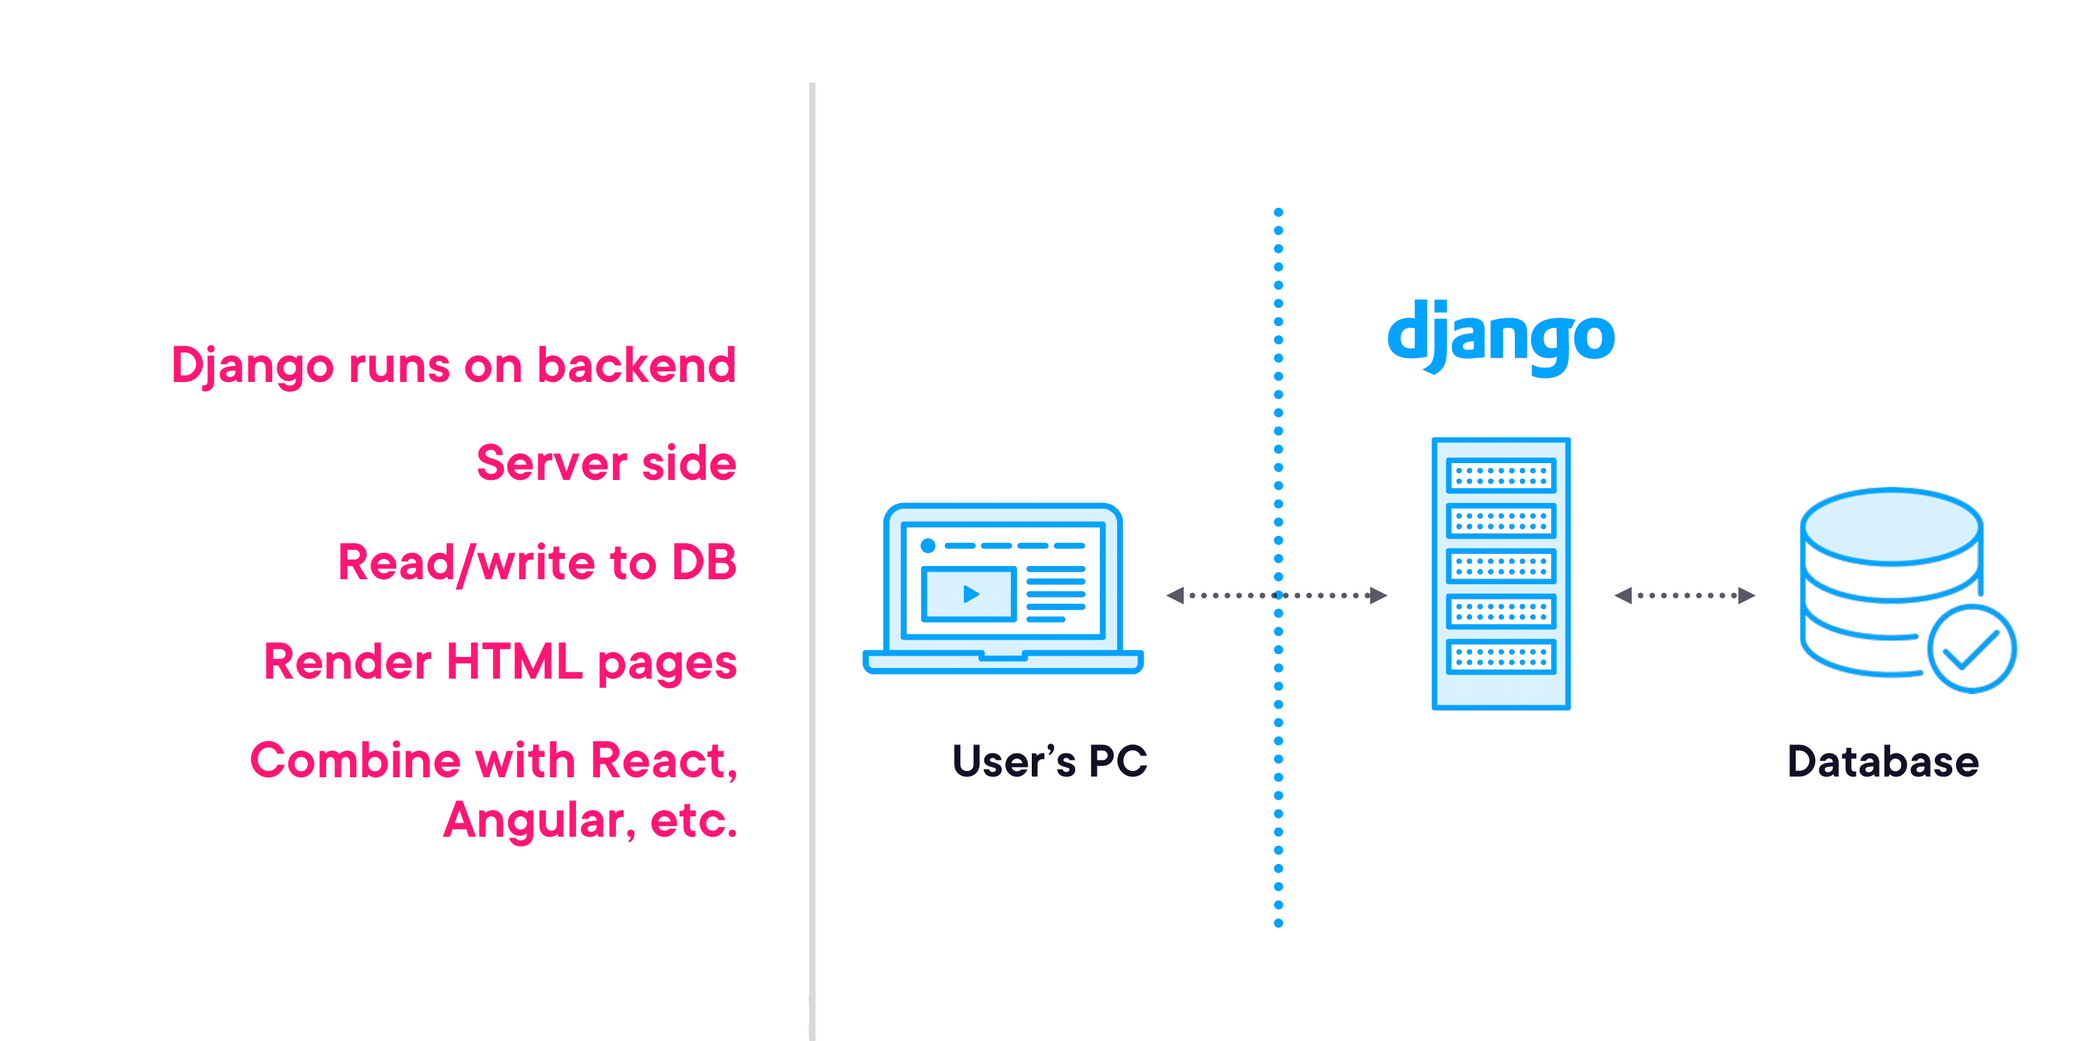

In [2]:
show('django_backend_arch-07.png', pct=70)

### 1.4 Built-in Features

Django ships with everything you need out of the box:


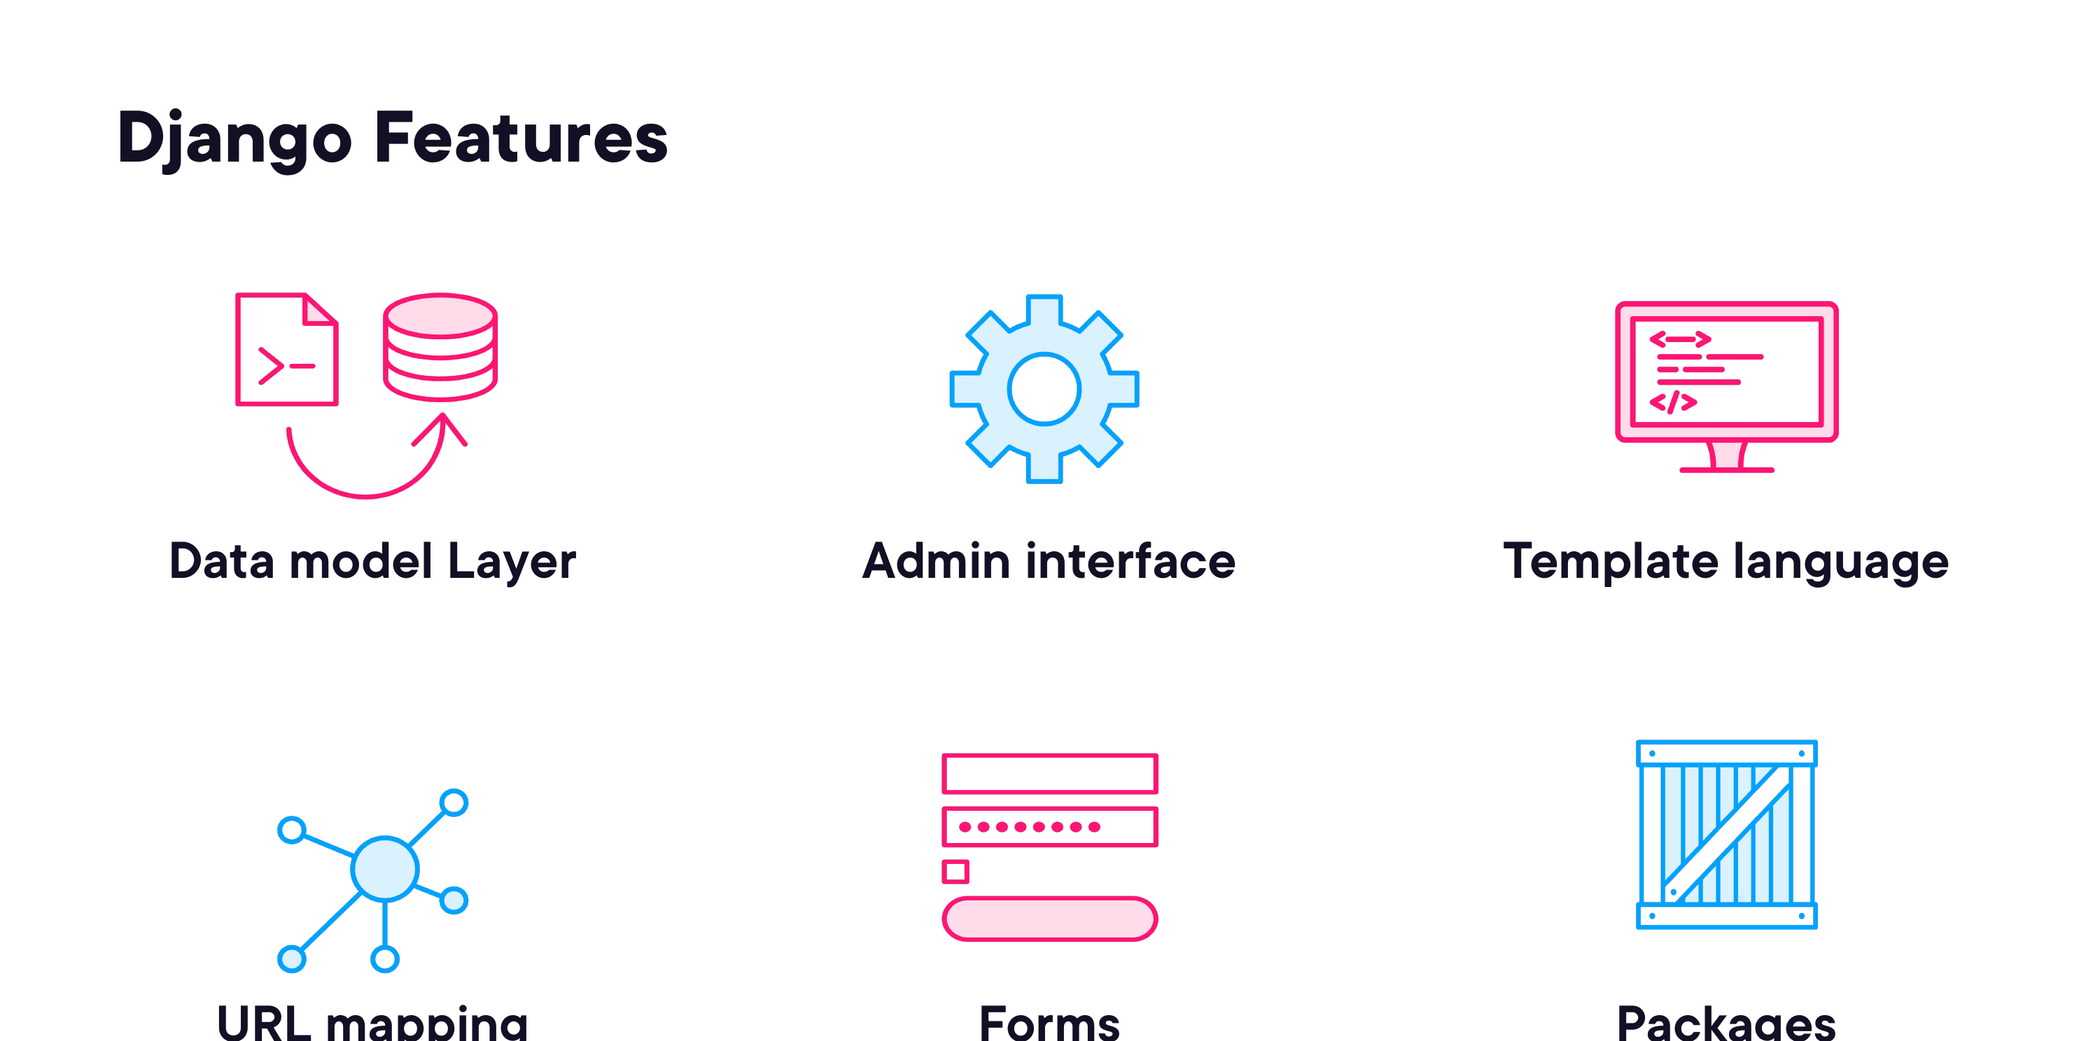

In [3]:
show('django_features-08.png', pct=70)

| Feature | Description |
|---|---|
| **Data model layer (ORM)** | Define Python classes → Django creates and manages the DB tables |
| **Admin interface** | Auto-generated CRUD UI for your models, zero config |
| **Template language** | Django Template Language (DTL) — generate HTML server-side |
| **URL mapping** | Map URL patterns to Python view functions in `urls.py` |
| **Forms** | Render HTML forms, validate input, save to DB |
| **Packages** | Huge ecosystem of third-party packages |
| **User authentication** | Built-in login, logout, permissions, groups |
| **HTTP session handling** | Cookie/DB-backed sessions out of the box |
| **Caching** | Multiple cache backends (memcached, Redis, DB, file) |
| **Internationalization** | i18n/l10n support built in |

### 1.5 Prerequisites for Learning Django

Before diving in, you should know:

| Topic | What you need |
|---|---|
| **Python** | Basics of the language (functions, classes, modules) |
| **Web Development** | Basics of HTML |
| **Databases** | Tables, rows, primary keys; basic SQL (`SELECT`, `INSERT`, `WHERE`) |

---
## Part 2 — Structure of a Django Application

### 2.1 Supported Databases

Django ships with database backends for:
- **PostgreSQL**, **MariaDB**, **MySQL**, **Oracle**, **SQLite**
- With third-party packages: DB2, MS SQL, and more

> **SQLite is the default** — perfect for development; switch to PostgreSQL for production.

### 2.2 The MTV Pattern (Model-Template-View)

Django follows the **Model-Template-View** architecture (also called Model-View-Controller in other frameworks):


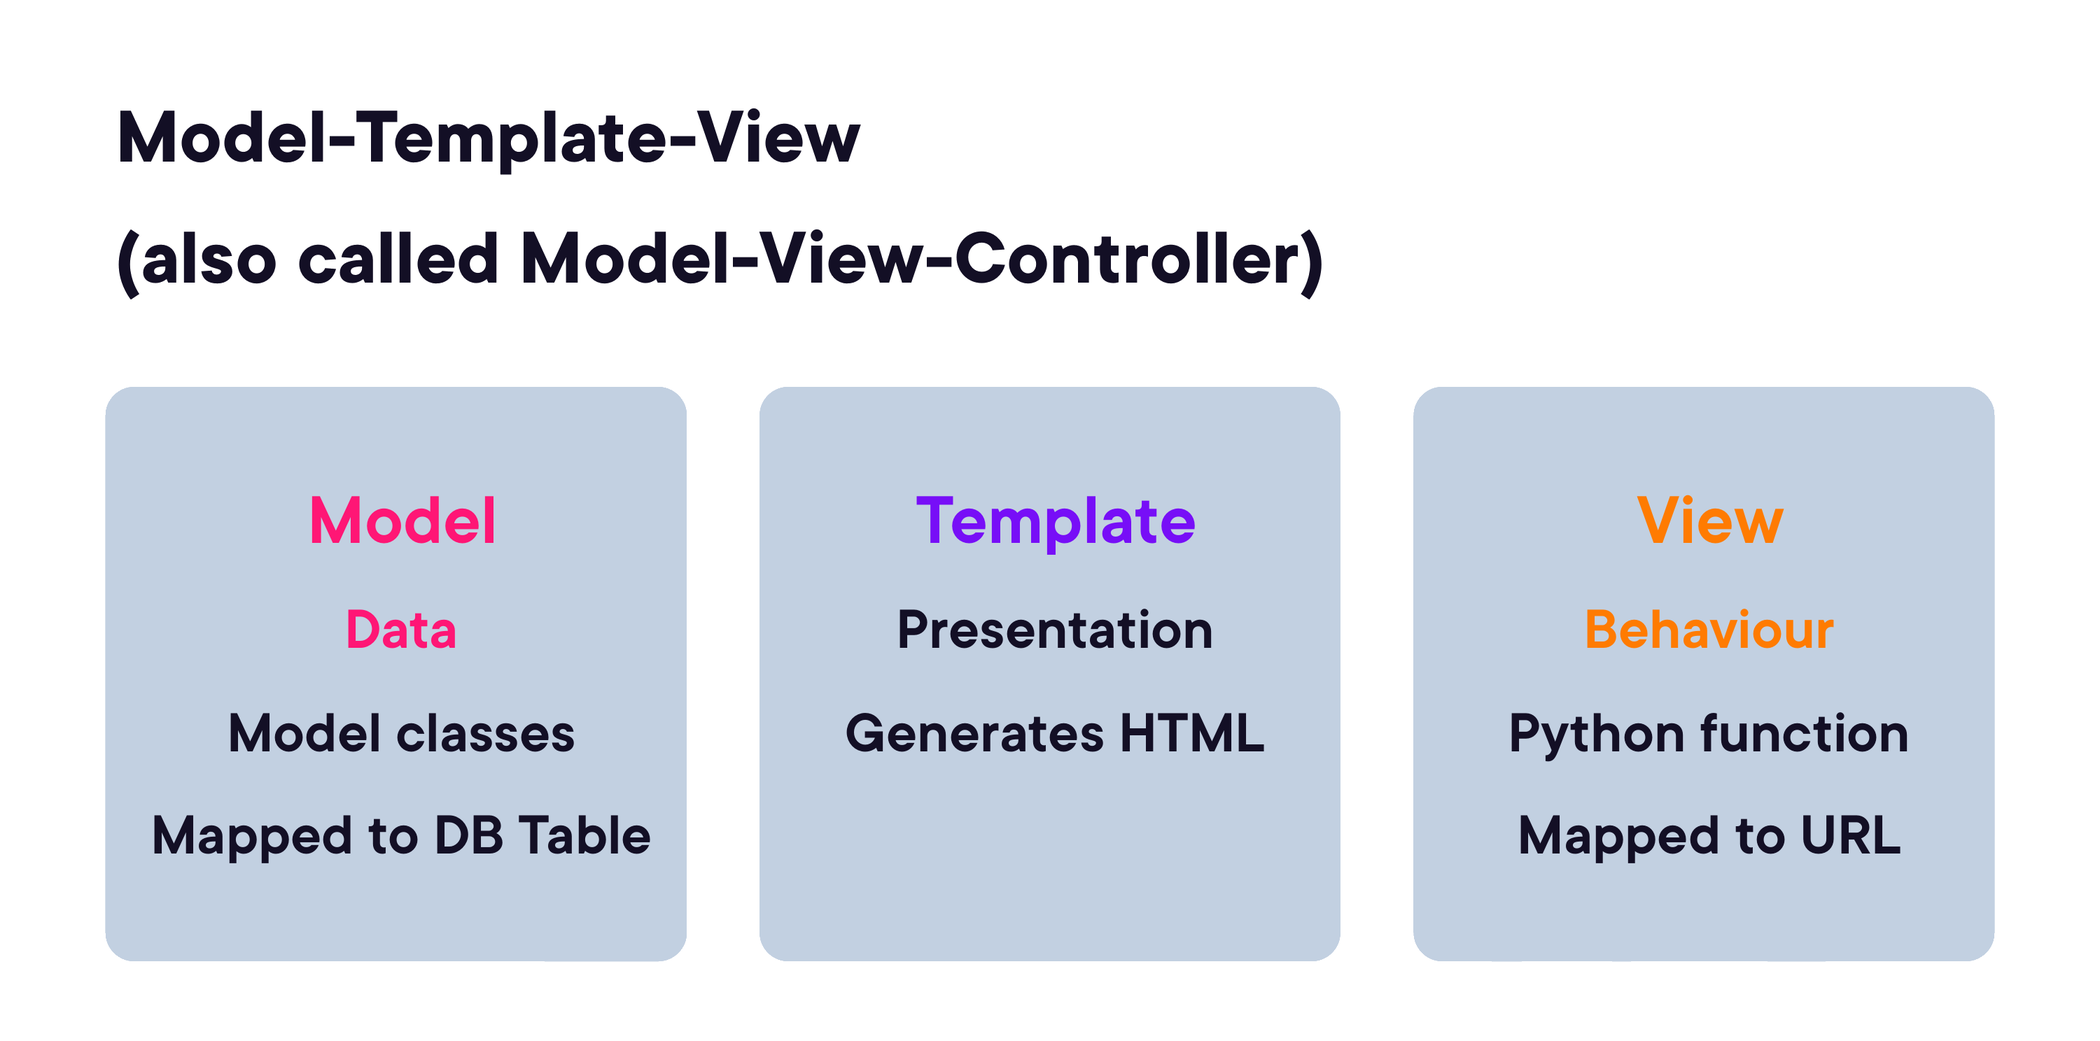

In [4]:
show('mtv_pattern-4.png', pct=70)

| Component | Role | Django file |
|---|---|---|
| **Model** | Data — Python class mapped to a database table | `models.py` |
| **Template** | Presentation — HTML file with DTL tags | `templates/*.html` |
| **View** | Behaviour — Python function/class mapped to a URL | `views.py` |

### 2.3 The Request–Response Cycle

When a browser requests a page, Django processes it like this:


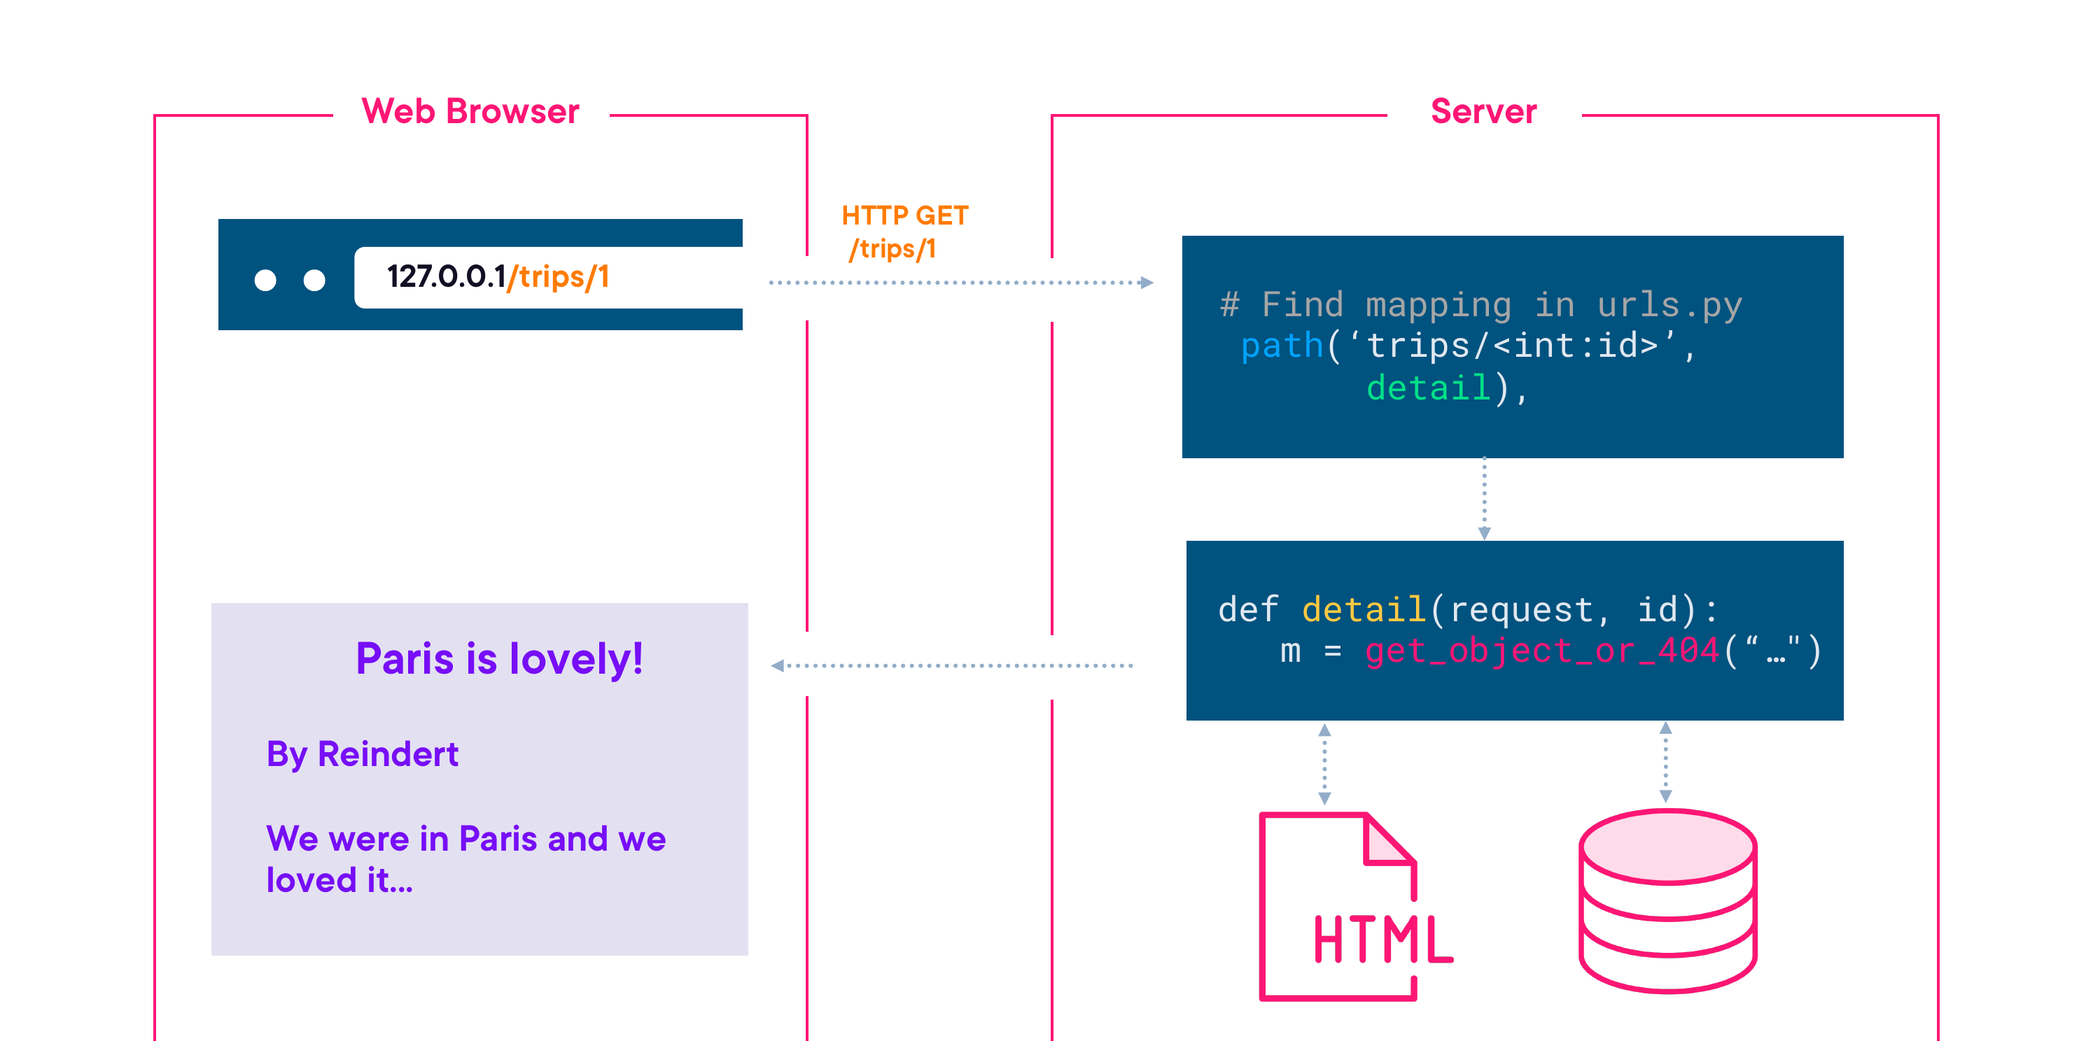

In [5]:
show('request_response_flow-5.png', pct=70)

**Step by step:**
1. Browser sends `HTTP GET /trips/1`
2. Django searches `urls.py` for a matching `path()` entry
3. The matched **view function** is called with the request and URL parameters
4. The view queries the **database** via a Model
5. The view renders a **template** with the data
6. Django returns the HTML **response** to the browser

### 2.4 Real Code: Travel Blog Demo

The demo project in `01/demos/travel_blog/` illustrates all three layers. Let's walk through each.

#### 2.4.1 Models (`trips/models.py`)

Each model class becomes a database table. Field types map to SQL column types.

```python
# trips/models.py — simplified for illustration
from django.conf import settings
from django.db import models
from django.utils import timezone
from django.urls import reverse


class Destination(models.Model):
    name = models.CharField(max_length=100)
    state = models.CharField(max_length=100, default="")
    country = models.CharField(max_length=100)

    def __str__(self):
        return f"{self.name}, {self.country}"


class Trip(models.Model):
    author = models.ForeignKey(settings.AUTH_USER_MODEL, on_delete=models.PROTECT)
    destination = models.ForeignKey(Destination, on_delete=models.PROTECT)
    title = models.CharField(max_length=100)
    intro_text = models.TextField()
    main_picture = models.ForeignKey('Picture', on_delete=models.PROTECT, blank=True)
    created_date = models.DateTimeField(default=timezone.now)
    from_date = models.DateField()
    to_date = models.DateField()

    class Meta:
        ordering = ["-from_date"]  # newest trips first

    def get_absolute_url(self):
        return reverse("trip_detail", kwargs={"pk": self.id})

    def __str__(self):
        return self.title


class Comment(models.Model):
    trip = models.ForeignKey(Trip, on_delete=models.CASCADE, related_name="comments")
    name = models.CharField("Your name", max_length=100)
    text = models.TextField("Your comment")
    created_date = models.DateTimeField(default=timezone.now)
```

**Key ORM concepts shown above:**
- `CharField`, `TextField`, `DateField`, `DateTimeField` — common field types
- `ForeignKey` — many-to-one relationship (joins)
- `on_delete=models.PROTECT` — prevent deletion of referenced records
- `on_delete=models.CASCADE` — cascade delete (delete comments when trip deleted)
- `class Meta` — ordering, uniqueness constraints, etc.
- `reverse()` — generate a URL from a named URL pattern

#### 2.4.2 Views (`trips/views.py`)

Views are Python functions (or classes) that receive an `HttpRequest` and return an `HttpResponse`.

```python
# trips/views.py
from django.shortcuts import render, get_object_or_404, redirect
from trips.models import Trip, Destination, Comment
from django.forms import modelform_factory


def landing_page(request):
    posts = Trip.objects.all()                              # ORM query — SELECT * FROM trips_trip
    destinations = Destination.objects.values_list("country", flat=True).distinct()
    return render(
        request, "landing_page.html",
        {"posts": posts, "destinations": destinations}      # pass data to template
    )


CommentForm = modelform_factory(Comment, fields=["name", "text"])  # auto-generated form


def detail_page(request, pk: int):
    post = get_object_or_404(Trip, pk=pk)                   # 404 if not found
    destinations = Destination.objects.values_list("country", flat=True).distinct()
    return render(
        request, "detail.html",
        {"post": post, "destinations": destinations, "comment_form": CommentForm()}
    )


def comment(request, pk: int):
    trip = get_object_or_404(Trip, pk=pk)
    if request.method == "POST":
        form = CommentForm(data=request.POST, initial={"trip_id": trip.id})
        if form.is_valid():
            form.instance.trip = trip
            form.save()                                     # writes to DB
    return redirect("trip_detail", pk=pk)                   # Post-Redirect-Get pattern
```

**Key patterns shown above:**
- `Model.objects.all()` — fetch all rows (QuerySet, lazy)
- `get_object_or_404()` — common shortcut: fetch or return HTTP 404
- `render()` — render a template with a context dict → `HttpResponse`
- `modelform_factory()` — create a Form class from a Model automatically
- `form.is_valid()` → `form.save()` — standard form handling flow
- `redirect()` — return an HTTP 302 redirect response

#### 2.4.3 URL Configuration (`travel_blog/urls.py`)

URLs are mapped to view functions in `urls.py` using `path()`.

```python
# travel_blog/urls.py
from django.contrib import admin
from django.conf.urls.static import static
from django.urls import path
from travel_blog import settings
from trips.views import landing_page, detail_page, comment

urlpatterns = [
    path("admin/", admin.site.urls),                         # built-in admin UI
    path("", landing_page, name="landing"),                  # root URL → landing_page view
    path("trips/<int:pk>", detail_page, name="trip_detail"), # <int:pk> is a URL parameter
    path("trips/comment/<int:pk>", comment, name="trip_comment"),
] + static(settings.MEDIA_URL, document_root=settings.MEDIA_ROOT)
```

**URL path converters:**

| Converter | Matches | Example |
|---|---|---|
| `<int:pk>` | Integer | `/trips/42` → `pk=42` |
| `<str:slug>` | Any non-empty string without `/` | `/trips/paris-trip` |
| `<slug:slug>` | Slug (letters, numbers, hyphens, underscores) | `/trips/my-paris-trip-2024` |
| `<uuid:id>` | UUID | `/items/0e3b... ` |

#### 2.4.4 Templates (`templates/base.html` excerpt)

Django templates use `{{ variable }}` for output and `{% tag %}` for logic.

```python
# Django Template Language (DTL) — not runnable Python, shown here for illustration
template_example = """
<!-- Loop over destinations passed from the view -->
{% for dest in destinations %}
    <a href="#" class="hover:bg-gray-400 rounded py-2 px-4 mx-2">{{ dest }}</a>
{% endfor %}

<!-- Template inheritance: child templates fill this block -->
{% block content %}
{% endblock %}

<!-- Conditional -->
{% if user.is_authenticated %}
    Welcome, {{ user.username }}!
{% else %}
    <a href="/login">Log in</a>
{% endif %}
"""
print(template_example)
```

**Key DTL constructs:**

| Construct | Syntax | Purpose |
|---|---|---|
| Variable output | `{{ variable }}` | Render a value |
| Attribute access | `{{ post.title }}` | Access object attributes |
| For loop | `{% for x in list %}...{% endfor %}` | Iterate |
| Conditional | `{% if cond %}...{% endif %}` | Branch |
| Block | `{% block name %}...{% endblock %}` | Template inheritance slot |
| Extends | `{% extends "base.html" %}` | Inherit from a parent template |
| URL | `{% url 'trip_detail' pk=post.id %}` | Reverse-resolve a named URL |

### 2.5 Django Project vs. App

A Django **project** is the top-level container (settings, root URLs). Inside a project you have multiple **apps** — self-contained modules that each handle a domain of functionality.

```
travel_blog/          ← project
├── manage.py
├── travel_blog/      ← project package (settings, root urls)
│   ├── settings.py
│   ├── urls.py
│   ├── wsgi.py
│   └── asgi.py
├── trips/            ← app: trips domain
│   ├── models.py
│   ├── views.py
│   ├── admin.py
│   ├── apps.py
│   └── migrations/
└── restaurants/      ← app: restaurants domain
    ├── models.py
    └── ...
```

**Rule of thumb:** each app should do one thing. Apps are reusable across projects.

### 2.6 Migrations

Migrations keep your database schema in sync with your models. Django generates them automatically.

```bash
# After changing models.py:
python manage.py makemigrations   # generates migration file
python manage.py migrate          # applies it to the DB

# Start a project
django-admin startproject myproject
# Create an app
python manage.py startapp myapp
# Run the development server
python manage.py runserver
# Create a superuser for the admin
python manage.py createsuperuser
```

---
## Part 3 — Choosing Django

### 3.1 Django's Strengths

| Strength | Why it matters |
|---|---|
| **Backend web framework** | Full server-side stack in one package |
| **Python** | Readable, expressive, huge ecosystem |
| **Complete** | ORM, admin, auth, forms, sessions — no plugin hunting |
| **Mature** | 20+ years of production use, well-understood patterns |
| **Active community** | Large third-party package ecosystem, regular LTS releases |

**Release cadence:**
- New feature releases: once or twice per year
- Bugfix releases: ~once per month

### 3.2 Backend, Not Frontend

Django renders server-side HTML. For richer interactive UIs you can pair it with:
- **React** or **Angular** — full SPA, Django as an API backend (use Django REST Framework)
- **HTMX** — add interactivity with minimal JS, keep server-side rendering
- **Vue.js** — progressive enhancement approach

### 3.3 Ecosystem

Django has a vast ecosystem of third-party packages:

| Package | Purpose |
|---|---|
| **Django REST Framework (DRF)** | Build REST APIs with serializers, viewsets, authentication |
| **Django Channels** | WebSockets, async support |
| **django-cms** | Full CMS on top of Django |
| **Wagtail** | Popular CMS alternative |
| **Celery** | Async task queues |
| **django-allauth** | Social auth (OAuth) |

> Browse more at [awesomedjango.org](http://awesomedjango.org)

### 3.4 Alternatives Comparison

#### Python alternatives

| Framework | Type | When to choose |
|---|---|---|
| **Django** | Full-stack | Content sites, admin-heavy apps, teams that want batteries included |
| **Flask** | Microframework (minimal features, Jinja templates) | Small/simple projects, when you want full control |
| **FastAPI** | REST API framework (high performance, async) | Highly performant REST APIs; small featureset, needs external packages |
| **Pyramid** | Flexible middleware-based | Complex, bespoke requirements |
| **Web2py / Bottle** | Lightweight | Tiny projects, scripting |

#### REST APIs specifically
- Use **Django + DRF** when you need the full admin, ORM, auth stack alongside the API
- Use **Flask** or **FastAPI** when you want a lighter, purely API-focused setup

#### Cross-language alternatives

| Framework | Language | Django comparison |
|---|---|---|
| **Laravel** | PHP | Very similar featureset; Django has better performance and the admin panel |
| **.NET Core** | C# | C# has better raw performance; Django wins on developer experience and ORM ergonomics |

---
## Summary Cheatsheet

### Core Concepts at a Glance

```
Browser  →  urls.py  →  views.py  →  models.py  →  Database
                ↓              ↓
           URL pattern    Template
              matched      rendered
```

| File | Responsibility |
|---|---|
| `models.py` | Define data structure (M in MTV) |
| `views.py` | Business logic, queries DB, renders template (V in MTV) |
| `templates/*.html` | Presentation layer (T in MTV) |
| `urls.py` | Route URLs to view functions |
| `admin.py` | Register models for the auto admin |
| `migrations/` | Database schema change history |
| `settings.py` | Project-wide configuration |

### Essential `manage.py` Commands

```bash
python manage.py runserver          # start dev server on :8000
python manage.py makemigrations     # generate migration from model changes
python manage.py migrate            # apply migrations to DB
python manage.py createsuperuser    # create admin user
python manage.py shell              # interactive Python shell with Django loaded
python manage.py startapp <name>    # scaffold a new app
python manage.py test               # run tests
```

### ORM Quick Reference

```python
# Fetch all
Trip.objects.all()

# Filter
Trip.objects.filter(destination__country="France")

# Get one or 404
get_object_or_404(Trip, pk=pk)

# Order
Trip.objects.order_by("-from_date")

# Create
trip = Trip.objects.create(title="Paris", ...)

# Update
Trip.objects.filter(pk=1).update(title="Updated")

# Delete
Trip.objects.filter(pk=1).delete()
```

### Next Steps

After finishing this Big Picture module, continue with:
- **Django Fundamentals** (Reindert-Jan Ekker) — deep dives into each Django component
- Official Django docs: [docs.djangoproject.com](https://docs.djangoproject.com)